# Difference Finite Scheme derived from MRT-Hermite Lattice Boltzmann for Convective-Diffusive Equation

Based on the works of {cite:t}`bellotti2022finite` and {cite:t}`chen2023fourth`, we will develop a difference finite description of lattice Boltzmann equation in the multi-relaxation-times (MRT) framework.

## MRT Lattice Boltzmann equation for Convective-Diffusive Equation

To describe convective-diffusive problems, the MRT lattice Boltzmann formulation is described by:

$$
f_i( x_{\alpha} + e_{i,\alpha} \delta t, t+\delta t) = f_i(x_{\alpha}, t)  - (\textbf{M}^{-1}\textbf{S}\textbf{M})_{ik}\left( f_{k} - f_{k}^{eq}  \right), 
$$(MRT-Herm-LB-conv-df-Eq)

where $\textbf{M}$ is matrix of moments, $\textbf{S}$ is the diagonal matrix of relaxation times, and $\textbf{M}^{-1}$ is the inverse matrix of $\textbf{M}$. Considering the problem description in a lattice D1Q3, we have:

$$
\textbf{M} =\begin{pmatrix} 1 \\ e_{i,x} \\ e_{i,x}^{2}-1/3 \end{pmatrix} =\begin{pmatrix} 1 & 1 & 1 \\ 0 & 1   & -1 \\ -1/3  & 2/3 & 2/3 \end{pmatrix},  \qquad \qquad  \textbf{S} = \begin{pmatrix} s_0 & 0   & 0 \\ 0   & s_1 & 0 \\ 0   & 0   & s_2 \end{pmatrix},  \qquad \qquad \textbf{M}^{-1}=\begin{pmatrix}\dfrac{2}{3} & 0 & -1 \\ \dfrac{1}{6} & \dfrac{1}{2} & \dfrac{1}{2} \\ \dfrac{1}{6} & -\dfrac{1}{2} & \dfrac{1}{2} \end{pmatrix}.
$$

The equilibrium distribution function is defined by

$$
f^{eq}_{i} = w_{i}\left( u + \frac{e_{i,\alpha} B_{\alpha}}{c_{s}^{2}} + \frac{ \left( c_{s}^{2}C\delta_{\alpha\beta} + \Lambda_{\alpha\beta} - c_{s}^{2}u\delta_{\alpha\beta} \right) \left( e_{i,\alpha}e_{i,\beta} - c_{s}^{2}\delta_{\alpha\beta} \right)}{2c_{s}^{4}}  \right),
$$

where $\Lambda_{\alpha\beta}$ is a correction term defined by

$$
\Lambda_{\alpha\beta} = \displaystyle\int  B_{\alpha}^{'}B_{\beta}^{'}  du = \displaystyle\int \left(\displaystyle\frac{\partial B_{\alpha}}{\partial u} \displaystyle\frac{\partial B_{\beta}}{\partial u} \right) du.
$$

In [33]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from __future__ import division
from sympy import *
import numpy as np
from sympy import S, collect, expand, factor, Wild
from sympy import fraction, Rational, Symbol
from sympy import symbols, sqrt, Rational
import sympy as sp
from IPython.display import display, Math, Latex
%run ~/Desktop/Bazarin-R.L.M.-AcademicDocumentation/docs/source/modules/eq_funcs.ipynb
#-------------------------------------------------Símbolos----------------------------------------------
omega, u, B, w, C, Lamb = symbols('omega, u, B_{\\alpha}, w, C, \\Lambda_{\\alpha\\beta}')
wi, cx, cy, cs = symbols('w_{i} c_{x} c_{y} c_{s}')
fi, f0, f1, f2  = symbols('f_{i} f_{0} f_{1} f_{2}')
#-------------------------------------------------Funções----------------------------------------------
feq = Function('feq')(wi, cx, cy)
fneq = Function('fneq')(wi, cx, cy)
f = Function('f')(fi)
#----------------------------------------------Lattice-D2Q9---Variáveis----------------------------------------------
fi=np.array([f0,f1,f2])
w0=Rational(4,6);w1=Rational(1,6)
wi=np.array([w0,w1,w1])
cx=np.array([0,1,-1])
as2=Rational(3)
cs2=1/as2
#-------------------------------------------------Calc.Func------------------------------------------------
f= fi
feq=wi*(u + cx*B/cs2 + ((C*cs2 + Lamb -u*cs2)*(cx*cx-cs2))/(2*cs2**2))
# feq2=wi*(u + cx*B/cs2 + (u*C**2*(cx*cx-cs2))/(2*cs2**2))
# feq=wi*(u + cx*B/cs2 )
# feq4=wi*(u + cx*u*C/cs2 + (u*C**2*(cx*cx-cs2))/(2*cs2**2))

The different orders of equilibrium moments can be recovered by:

##### Raw Moments

In [34]:
a0=simplify(sum(feq))
ax=simplify(sum(feq*cx))
axx=simplify(sum(feq*cx*cx))
axxx=simplify(sum(feq*cx*cx*cx))
display(Math(r"\begin{gathered}"
             r"\underbrace{\sum_{i=0} f_{i}^{eq} =\sum_{i=0} f_{i} }_{\textrm{Zero-Order Moment}} =" +  sp.latex(a0) 
            +r",\quad \underbrace{\sum_{i=0} f_{i}^{eq}c_{i,x} }_{\textrm{x-First-Order Moment}} =" +  sp.latex(ax)
            +r",\quad \underbrace{\sum_{i=0} f_{i}^{eq} c_{i,x}c_{i,x} }_{\textrm{xx-Second-Order Moment}} =" +  sp.latex(axx)
            +r",\quad \underbrace{\sum_{i=0} f_{i}^{eq} c_{i,x}c_{i,x}c_{i,x} }_{\textrm{xxx-Third-Order Moment}} =" +  sp.latex(axxx) 
            +r".\end{gathered}"
            ))

<IPython.core.display.Math object>

##### Hermite Moments

In [35]:
aH0=simplify(sum(feq))
aHx=simplify(sum(feq*cx))
aHxx=simplify(sum(feq*(cx*cx-cs2)))
aHxxx=simplify(sum(feq*(cx*cx-3*cs2)*cx))
display(Math(r"\begin{gathered}"
             r"\underbrace{\sum_{i=0} f_{i}^{eq} =\sum_{i=0} f_{i} }_{\textrm{Zero-Order Hermite Moment}} =" +  sp.latex(aH0) 
            +r",\quad \quad \underbrace{\sum_{i=0} f_{i}^{eq}c_{i,x} }_{\textrm{x-First-Order Hermite Moment}} =" +  sp.latex(aHx) 
            +r",\quad \quad\underbrace{\sum_{i=0} f_{i}^{eq} \left(c_{i,x}c_{i,x} - c_{s}^{2} \right) }_{\textrm{xx-Second-Order Hermite Moment}} =" +  sp.latex(aHxx)
            +r",\quad \quad \underbrace{\sum_{i=0} f_{i}^{eq} \left(c_{i,x}c_{i,x} - 3c_{s}^{2} \right) c_{i,x} }_{\textrm{xxx-Third-Order Hermite Moment}} =" +  sp.latex(aHxxx) 
            +r".\end{gathered}"
            ))

<IPython.core.display.Math object>

## FDM Interpretation in MRT Framework

Reinterpreting the Eq. {eq}`MRT-Herm-LB-conv-df-Eq` with a shift in distribution function direction:

$$
f_{i,x}^{t+1}  = f_{i,x-e_{i}}^{t}  - (\textbf{M}^{-1}\textbf{S}\textbf{M})_{ik}\left( f_{k,x-e_{i}}^{t} - f_{k,x-e_{i}}^{eq,t} \right) =   (\textbf{M}^{-1} (\textbf{I} -\textbf{S}) \textbf{M})_{ik} f_{k,x-e_{i}}^{t} + (\textbf{M}^{-1}\textbf{S}\textbf{M})_{ik} f_{k,x-e_{i}}^{eq,t}  , 
$$

where $f_i( x_{\alpha} + e_{i,\alpha} \delta t, t+\delta t)=f_{i,x+c_{i}}^{t+1}$ for simplificate the notation and $\textbf{I}$ is identity matrix. Defining the shift operator $T_{\Delta x}^{c_{i}}$, where $f_{k,x-e_{i}}^{t}= T_{\Delta x}^{c_{i}}[f_{k,x}^{t}]$, we can rewrite the above equation inside of the moments space:

$$
\textbf{m}_{k,x}^{t+1}  = \textbf{P}\textbf{m}_{k,x}^{t}  + \textbf{Q}\textbf{m}_{k,x}^{eq,t}, 
$$(pre-MRT-Herm-LB-conv-df-Eq)

where $\textbf{m}_{k,x}^{t}=M_{ik}f_{i,x}^{t}$, $k$ is the index of moments in the space moment, $\textbf{T}:= \textbf{M} (diag\left( T_{\Delta x}^{c_{0}}, T_{\Delta x}^{c_{1}}, T_{\Delta x}^{c_{2}} \right)) \textbf{M}^{-1}$, $\textbf{P}:=\textbf{T}(\textbf{I}-\textbf{S})$, and , $\textbf{Q}:=\textbf{T}\textbf{S}$. The matrices are given by:

In [36]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np

fic, f0c, f1c, f2c = symbols(['f_{i\,x+c_{i}}^t','f_{0\,x+c_{i}}^t','f_{1\,x+c_{i}}^t','f_{2\,x+c_{i}}^t'])
f0tp1, f1tp1, f2tp1 = symbols(['f_{0\,x}^{t+1}','f_{1\,x}^{t+1}','f_{2\,x}^{t+1}'])
f0, f1, f2 = symbols(['f_{0\,x}^t','f_{1\,x}^t','f_{2\,x}^t'])
f0m1, f1m1, f2m1, f0p1, f1p1, f2p1 = symbols(['f_{0\,x-1}^t','f_{1\,x-1}^t','f_{2\,x-1}^t','f_{0\,x+1}^t','f_{1\,x+1}^t','f_{2\,x+1}^t'])
f0m1t1, f1m1t1, f2m1t1, f0p1t1, f1p1t1, f2p1t1 = symbols(['f_{0\,x-1}^{t-1}','f_{1\,x-1}^{t-1}','f_{2\,x-1}^{t-1}','f_{0\,x+1}^{t-1}','f_{1\,x+1}^{t-1}','f_{2\,x+1}^{t-1}'])
f0t1 = symbols('f_{0\,x}^{t-1}')
w0, w1, w2 = symbols(['w_0','w_1','w_2'])
s0, s1, s2, s3, s4, s5, s6, s7, s8 = symbols(['s_0','s_1','s_2','s_3','s_4','s_5','s_6','s_7','s_8'])
phi, phic, phim1, phip1 = symbols(['\\phi_{x}^{t}','\\phi_{x-c_{i}}^{t}','\\phi_{x-1}^{t}','\\phi_{x+1}^{t}'])
phitp1, phit1, phit2= symbols(['\\phi_{x}^{t+1}','\\phi_{x}^{t-1}','\\phi_{x}^{t-2}'])
phim1t1,phip1t1= symbols(['\\phi_{x-1}^{t-1}','\\phi_{x+1}^{t-1}'])
Tc0, Tc1, Tc2= symbols([r'T_{\Delta_{x}}^{c_{0}}','T_{\Delta_{x}}^{c_{1}}','T_{\Delta_{x}}^{c_{2}}'])
cx=np.array([0,1,-1])
wi=np.array([w0,w1,w2])
wiM=Matrix([w0,w1,w2])
fi=np.array([f0,f1,f2])
fM = Matrix([f0,f1,f2])
ficM = Matrix([f0c,f1c,f2c])
I=eye(3)
Tc = Matrix([I[0,:]*Tc0,I[1,:]*Tc1,I[2,:]*Tc2])
SM=Matrix([I[0,:]*s0,I[1,:]*s1,I[2,:]*s2])
feq=phi*wi
feqM=Matrix([feq[0],feq[1],feq[2]])
feqc=wiM*phic
m0=np.array([1,1,1])
m1=cx
m2=cx*cx - Rational(1,3)
M=np.array([m0,m1,m2])
MM=Matrix([m0,m1,m2])
MMinv=MM.inv()

In [37]:
TM=sp.simplify(MM*Tc*MMinv)
P=sp.simplify(TM*(I-SM))
Q=sp.simplify(TM*SM)

display(Math(r"\textbf{T} =" +  sp.latex(TM) +"," ))
display(Math(r"\textbf{P} =" +  sp.latex(P) +"," ))
display(Math(r"\textbf{Q} =" +  sp.latex(Q) +"." ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

By the Eq. {eq}`pre-MRT-Herm-LB-conv-df-Eq` can be shifted in time, we recursively over $n$ timestep replace the shifted time function in it:

$$
\underbrace{ \textbf{m}_{k,x}^{t+1}  = \textbf{P}\textbf{m}_{k,x}^{t}  + \textbf{Q}\textbf{m}_{k,x}^{eq,t} \quad \rightarrow \quad  \textbf{m}_{k,x}^{t}  = \textbf{P}\textbf{m}_{k,x}^{t-1}  + \textbf{Q}\textbf{m}_{k,x}^{eq,t-1} }_{\textrm{Time Shift}} \qquad  \textrm{Recursive Substitution $n$ times:} \qquad \textbf{m}_{k,x}^{t+1}  = \textbf{P}^{n}\textbf{m}_{k,x}^{t-n+1}  + \displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-l}.
$$(pre-MRT-Herm-LB-conv-df-Eq-s2)

The next steps follow in orde to employ the Calay-Hamilton theorem {cite:p}`bellotti2022finite`. In htis way, we need to find the characteristical polinomial $\mathcal{X}_{P}$ of the matrix $\textbf{P}$ (the definition of characteristical polinomial are presented in toogle below), given by:

```{toggle}
The characteristic polynomial of a square matrix $(P \in \mathbb{R}^{n \times n})$ (or $(\mathbb{C}^{n \times n}))$ is defined as:

$$
\boxed{\mathcal{X}_{P}(X) = \det(X I - P)} \qquad \rightarrow \qquad \mathcal{X}_{P}(X) = \sum_{i=0}^{n} X^{i}\gamma^{i} 
$$

where $\gamma_{i}$ are the polynomial coefficients.

```

$$
\mathcal{X}_{P} = \gamma_{3}X^{3} +  \gamma_{2}X^{2} +  \gamma_{1}X^{1} +  \gamma_{0},
$$

where all the polynomial coefficients $\gamma_{i}$ are shifted by $T_{\Delta x}^{c_{0}}$:

In [38]:
from sympy import Matrix, symbols
X = symbols('X')
cp = P.charpoly(X)
# cp.as_expr() 
gamma3=Tc0
gamma2=sp.collect(cp.all_coeffs()[1],[s2,s1,s0])
gamma1=sp.simplify(sp.collect(cp.all_coeffs()[2],[s2*s1, s2, s1,s0]).subs(s0,0).subs(Tc1*Tc2,Tc0).subs(Tc0,1)).subs(2,2*Tc0).subs(1,Tc0)
gamma0=sp.factor(sp.collect(cp.all_coeffs()[3],[s2*s1, s2, s1,s0]).subs(s0,0).subs(Tc1*Tc2,Tc0).subs(Tc0,1))*Tc0

display(Math(r"\gamma_{3} =" +  sp.latex(gamma3) +"," ))
display(Math(r"\gamma_{2} =" +  sp.latex(gamma2) +"," ))
display(Math(r"\gamma_{1} =" +  sp.latex(gamma1) +"," ))
display(Math(r"\gamma_{0} =" +  sp.latex(gamma0) +"." ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [39]:
gamma3=Tc0
gamma2=sp.collect(cp.all_coeffs()[1],[s2,s1,s0])
gamma1=sp.simplify(sp.collect(cp.all_coeffs()[2],[s2*s1, s2, s1,s0]))#.subs(s0,0).subs(Tc1*Tc2,Tc0).subs(Tc0,1)).subs(2,2*Tc0).subs(1,Tc0)
gamma0=sp.collect(cp.all_coeffs()[3],[s2*s1, s2, s1,s0])#.subs(s0,0).subs(Tc1*Tc2,Tc0).subs(Tc0,1))*Tc0

display(Math(r"\gamma_{3} =" +  sp.latex(gamma3) +"," ))
display(Math(r"\gamma_{2} =" +  sp.latex(gamma2) +"," ))
display(Math(r"\gamma_{1} =" +  sp.latex(gamma1) +"," ))
display(Math(r"\gamma_{0} =" +  sp.latex(gamma0) +"." ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

To reach the above coeficient results, were considered: $T_{\Delta x}^{c_{1}}T_{\Delta x}^{c_{2}}=T_{\Delta x}^{c_{0}}$; $T_{\Delta x}^{c_{1}}T_{\Delta x}^{c_{0}}=T_{\Delta x}^{c_{1}}$; $T_{\Delta x}^{c_{2}}T_{\Delta x}^{c_{0}}=T_{\Delta x}^{c_{2}}$.Defined the characteristical polynomial, we multiply both sides of Eq. {eq}`pre-MRT-Herm-LB-conv-df-Eq-s2` by $\sum_{n=0}^{q}\gamma_{n}$ (where $q$ is the number of lattice velocities) and perform a time shift by change the time variable $t$ to $\tilde{t}+n=t+1$:

$$
\begin{array}{c}
\textbf{m}_{k,x}^{t+1}  = \textbf{P}^{n}\textbf{m}_{k,x}^{t-n+1}  + \displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-l} \qquad \rightarrow \qquad \textbf{m}_{k,x}^{\tilde{t}+n}  = \textbf{P}^{n}\textbf{m}_{k,x}^{\tilde{t}}  + \displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,\tilde{t}+n-1-l} \qquad \rightarrow \\
\displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{\tilde{t}+n}  = \displaystyle\sum_{n=0}^{q}\gamma_{n}\textbf{P}^{n}\textbf{m}_{k,x}^{\tilde{t}}  + \displaystyle\sum_{n=0}^{q}\gamma_{n} \left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,\tilde{t}+n-1-l}\right),
\end{array}
$$

by applying the Calay-Hamilton theorem, that imlpie $\sum_{n=0}^{q}\gamma_{n}\textbf{P}^{n}=0$:

$$
\displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{\tilde{t}+n}  = \underbrace{\left(\displaystyle\sum_{n=0}^{q}\gamma_{n}\textbf{P}^{n}\right)}_{=0}\textbf{m}_{k,x}^{\tilde{t}}  + \displaystyle\sum_{n=0}^{q}\gamma_{n}\left( \displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,\tilde{t}+n-1-l} \right) \qquad \rightarrow \qquad \displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{\tilde{t}+n}  =  \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,\tilde{t}+n-1-l}\right),
$$

applying a second time shift by change tha variable back to $\tilde{t}+q=t+1$ and expanding the left hand-side term to isolate the time $t+1$:

$$
\begin{array}{c}
\displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{\tilde{t}+n}  =  \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,\tilde{t}+n-1-l}\right)  \qquad \rightarrow \qquad \displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{t+1-q+n}  =  \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-q+n-l}\right) \qquad \rightarrow \\
\displaystyle\sum_{n=0}^{q}\gamma_{n} \textbf{m}_{k,x}^{t+1-q+n}  =  \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-q+n-l}\right) \qquad \rightarrow \qquad \gamma_{q} \textbf{m}_{k,x}^{t+1}  = -\displaystyle\sum_{n=0}^{q-1}\gamma_{n} \textbf{m}_{k,x}^{t+1-q+n} + \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-q+n-l}\right),
\end{array}
$$

the last sum term can be rewritten by

$$
\gamma_{q} \textbf{m}_{k,x}^{t+1}  = -\displaystyle\sum_{n=0}^{q-1}\gamma_{n} \textbf{m}_{k,x}^{t+1-q+n} + \displaystyle\sum_{n=0}^{q}\gamma_{n}\left(\displaystyle\sum_{l=0}^{n-1}\textbf{P}^{l}\textbf{Q}\textbf{m}_{k,x}^{eq,t-q+n-l}\right) \qquad \rightarrow \qquad \gamma_{q} \textbf{m}_{k,x}^{t+1}  = -\displaystyle\sum_{n=0}^{q-1}\gamma_{n} \textbf{m}_{k,x}^{t+1-q+n} + \displaystyle\sum_{n=0}^{q-1}\left(\displaystyle\sum_{l=0}^{n}\gamma_{q+l-n}\textbf{P}^{l}\right)\textbf{Q}\textbf{m}_{k,x}^{eq,t-n}.
$$

In [40]:
import sympy as sp
# ---------------- indices / parameters ----------------
q = sp.Symbol('q', integer=True, positive=True)
n, l = sp.symbols('n l', integer=True, nonnegative=True)
m1s = sp.Symbol('m^{t+1}_{k,x}')
m0s = sp.Symbol('m^{t}_{k,x}')
mm1s = sp.Symbol('m^{t-1}_{k,x}')
mm2s = sp.Symbol('m^{t-2}_{k,x}')
meq0s = sp.Symbol('m^{eq,t}_{k,x}')
meqm1s = sp.Symbol('m^{eq,t-1}_{k,x}')
meqm2s = sp.Symbol('m^{eq,t-2}_{k,x}')

# gamma_j as an indexed coefficient sequence
gammas = sp.IndexedBase('gamma')   # gamma[j] means γ_j

# Abstract time-shifted moments:
# m(s)    := m_{k,x}^{t+s}
# meq(s)  := m_{k,x}^{eq, t+s}
ms   = sp.Function('m')
meqs = sp.Function('m_eq')

# Operators/matrices (leave as Symbols unless you need matrix algebra)
Ps = sp.Symbol('P')
Qs = sp.Symbol('Q')

# ---------------- build the equation ----------------
lhs = gammas[q] * ms(1)  # γ_q * m^{t+1}

rhs1 = -sp.summation(gammas[n] * ms(1 - q + n), (n, 0, q-1))

inner = sp.summation(gammas[q + l - n] * Ps**l, (l, 0, n))
rhs2  = sp.summation(inner * Qs * meqs(-n), (n, 0, q-1))

# eq = sp.Eq(lhs, rhs1 + rhs2)
eq = rhs1 + rhs2
eq1 = lhs.subs({ms(1):m1s,gammas[q]:gammas[3]})

# ---------------- expand for a concrete q ----------------
# SymPy can only 'doit' finite sums once q is a number.
q_val = 3  # <-- change to 2,3,4,... as needed
eq_expanded = sp.expand(eq.subs(q, q_val).doit())

# print(f"\nExpanded for q={q_val}:")
# display(eq_expanded)

eqsubs=eq_expanded.subs({ms(1):m1s,ms(0):m0s,ms(-1):mm1s,ms(-2):mm2s,meqs(0):meq0s,meqs(0):meq0s,meqs(-1):meqm1s,meqs(-2):meqm2s})
sp.Eq(eq1, eqsubs)

Eq(m^{t+1}_{k,x}*gamma[3], P**2*Q*m^{eq,t-2}_{k,x}*gamma[3] + P*Q*m^{eq,t-1}_{k,x}*gamma[3] + P*Q*m^{eq,t-2}_{k,x}*gamma[2] + Q*m^{eq,t-1}_{k,x}*gamma[2] + Q*m^{eq,t-2}_{k,x}*gamma[1] + Q*m^{eq,t}_{k,x}*gamma[3] - m^{t-1}_{k,x}*gamma[1] - m^{t-2}_{k,x}*gamma[0] - m^{t}_{k,x}*gamma[2])

Considering the solution for the moment $m^{t+1}_{0,x}$, the above equation is rewritten to:

$$
m^{t+1}_{0,x} \gamma_{3} = \left[P^{2} Q m^{eq,t-2}_{k,x} \gamma_{3}\right]_{k=0} + \left[P Q m^{eq,t-1}_{k,x} \gamma_{3}\right]_{k=0} + \left[P Q m^{eq,t-2}_{k,x} \gamma_{2}\right]_{k=0} + \left[Q m^{eq,t-1}_{k,x} \gamma_{2}\right]_{k=0} + \left[Q m^{eq,t-2}_{k,x} \gamma_{1}\right]_{k=0} + \left[Q m^{eq,t}_{k,x} \gamma_{3}\right]_{k=0} - m^{t-1}_{0,x} \gamma_{1} - m^{t-2}_{0,x} \gamma_{0} - m^{t}_{0,x} \gamma_{2}
$$(Momentum-Herm-exp-term-convec-diff)

In [41]:
import sympy as sp
# ---------------- indices / parameters ----------------
meq0k11s = sp.Symbol('m^{eq,t+1}_{0,x}')
meq0k0s = sp.Symbol('m^{eq,t}_{0,x}')
meq1k0s = sp.Symbol('m^{eq,t}_{1,x}')
meq2k0s = sp.Symbol('m^{eq,t}_{2,x}')
MeqM0s=Matrix([meq0k0s,meq1k0s,meq2k0s])
meq0k1s = sp.Symbol('m^{eq,t-1}_{0,x}')
meq1k1s = sp.Symbol('m^{eq,t-1}_{1,x}')
meq2k1s = sp.Symbol('m^{eq,t-1}_{2,x}')
MeqM1s=Matrix([meq0k1s,meq1k1s,meq2k1s])
meq0k2s = sp.Symbol('m^{eq,t-2}_{0,x}')
meq1k2s = sp.Symbol('m^{eq,t-2}_{1,x}')
meq2k2s = sp.Symbol('m^{eq,t-2}_{2,x}')
MeqM2s=Matrix([meq0k2s,meq1k2s,meq2k2s])
m0k11s = sp.Symbol('m^{t+1}_{0,x}')
m0k0s = sp.Symbol('m^{t}_{0,x}')
m0k1s = sp.Symbol('m^{t-1}_{0,x}')
m0k2s = sp.Symbol('m^{t-2}_{0,x}')
m1k0s = sp.Symbol('m^{t}_{1,x}')
m1k1s = sp.Symbol('m^{t-1}_{1,x}')
m1k2s = sp.Symbol('m^{t-2}_{1,x}')

In [42]:
termmeqm1=collect(simplify(expand(Q*MeqM1s*gamma2 + P*Q*MeqM1s))[0].subs(Tc0*Tc1,Tc1).subs(Tc0*Tc2,Tc2).subs(Tc1*Tc2,Tc0).subs(s0,0),[meq0k1s,meq1k1s,meq2k1s])
termmeqm1
display(Math(r"\left[ P Q m^{eq,t-1}_{k,x} \gamma_{3} \right]_{k=0} + \left[ Q m^{eq,t-1}_{k,x} \gamma_{2} \right]_{k=0} =" +  sp.latex(termmeqm1) +"," ))

<IPython.core.display.Math object>

In [43]:
# termmeqm2 = expand((P*Q)*MeqMs*gamma2 + Q*MeqMs*gamma1)[0]
termmeqm2 = expand( ((P*P)*Q)*MeqM2s*gamma3 + (P*Q)*MeqM2s*gamma2 + Q*MeqM2s*gamma1)[0].subs(Tc1*Tc2,Tc0).subs(Tc0,1).subs(s0,0)
display(Math(r"\left[ P^{2} Q m^{eq,t-2}_{k,x} \gamma_{3} \right]_{k=0} + \left[ PQ m^{eq,t-2}_{k,x} \gamma_{2} \right]_{k=0} + \left[ Q m^{eq,t-2}_{k,x} \gamma_{1} \right]_{k=0} =" +  sp.latex(termmeqm2) +"," ))

<IPython.core.display.Math object>

In [44]:
termmeqm3 = (Q*MeqM0s)[0].subs(s0,0)
# sp.Eq(Qs*meq0s*gammas[3], termmeqm3)
display(Math(r"\left[Q m^{eq,t}_{k,x} \gamma_{3} \right]_{k=0} =" +  sp.latex(termmeqm3) +"." ))

<IPython.core.display.Math object>

Replacing the terms in the Eq. {eq}`Momentum-Herm-exp-term-convec-diff`:

In [45]:
eqsubs2=(eqsubs.subs({meqm2s:0,Ps*Qs*meqm1s*gammas[3] + Qs*meqm1s*gammas[2]:termmeqm1,Qs*meq0s*gammas[3]:termmeqm3})
        .subs({m0s:m0k0s,mm1s:m0k1s,mm2s:m0k2s}).subs({gammas[3]:gamma3,gammas[2]:gamma2,gammas[1]:gamma1,gammas[0]:gamma0}).subs({s0:0})
        )
display_broken_equation(sp.Eq(eq1.subs({m1s:m0k11s,gammas[3]:gamma3}),eqsubs2), terms_per_line=1)

<IPython.core.display.Math object>

In [46]:
m0k0sdp1 = sp.Symbol('m^{t}_{0,x+1}')
m0k0sdm1 = sp.Symbol('m^{t}_{0,x-1}')
m1k0sdp1 = sp.Symbol('m^{t}_{1,x+1}')
m1k0sdm1 = sp.Symbol('m^{t}_{1,x-1}')
m0k1sdp1 = sp.Symbol('m^{t-1}_{0,x+1}')
m0k1sdm1 = sp.Symbol('m^{t-1}_{0,x-1}')
m1k1sdp1 = sp.Symbol('m^{t-1}_{1,x+1}')
m1k1sdm1 = sp.Symbol('m^{t-1}_{1,x-1}')

meq0k0sdp1 = sp.Symbol('m^{eq,t}_{0,x+1}')
meq0k0sdm1 = sp.Symbol('m^{eq,t}_{0,x-1}')
meq1k0sdp1 = sp.Symbol('m^{eq,t}_{1,x+1}')
meq1k0sdm1 = sp.Symbol('m^{eq,t}_{1,x-1}')
meq2k0sdp1 = sp.Symbol('m^{eq,t}_{2,x+1}')
meq2k0sdm1 = sp.Symbol('m^{eq,t}_{2,x-1}')

meq0k1sdp1 = sp.Symbol('m^{eq,t-1}_{0,x+1}')
meq0k1sdm1 = sp.Symbol('m^{eq,t-1}_{0,x-1}')
meq1k1sdp1 = sp.Symbol('m^{eq,t-1}_{1,x+1}')
meq1k1sdm1 = sp.Symbol('m^{eq,t-1}_{1,x-1}')
meq2k1sdp1 = sp.Symbol('m^{eq,t-1}_{2,x+1}')
meq2k1sdm1 = sp.Symbol('m^{eq,t-1}_{2,x-1}')

In [47]:
eqsubs3 = (collect(expand(eqsubs2).subs({Tc0:1}).subs({Tc1*Tc2:1})
                .subs({Tc2*m0k0s:m0k0sdp1,Tc1*m0k0s:m0k0sdm1})
                .subs({Tc2*m0k1s:m0k1sdp1,Tc1*m0k1s:m0k1sdm1})
                .subs({Tc2*m1k0s:m1k0sdp1,Tc1*m1k0s:m1k0sdm1})
                .subs({Tc2*m1k1s:m1k1sdp1,Tc1*m1k1s:m1k1sdm1})
                .subs({Tc2*meq0k0s:meq0k0sdp1,Tc1*meq0k0s:meq0k0sdm1})
                .subs({Tc2*meq1k0s:meq1k0sdp1,Tc1*meq1k0s:meq1k0sdm1})
                .subs({Tc2*meq2k0s:meq2k0sdp1,Tc1*meq2k0s:meq2k0sdm1})
                .subs({Tc2*meq0k1s:meq0k1sdp1,Tc1*meq0k1s:meq0k1sdm1})
                .subs({Tc2*meq1k1s:meq1k1sdp1,Tc1*meq1k1s:meq1k1sdm1})
                .subs({Tc2*meq2k1s:meq2k1sdp1,Tc1*meq2k1s:meq2k1sdm1})
                ,[m0k2s, m0k0sdp1,m0k0sdm1,m0k0s, m1k0sdp1,m1k0sdm1,m1k0s, m0k1sdm1,m0k1sdp1,m0k1s, m1k1sdm1,m1k1sdp1,m1k1s, 
                  meq0k0sdm1,meq0k0sdp1,meq0k0s, meq1k0sdm1,meq1k0sdp1,meq1k0s, meq2k0sdm1,meq2k0sdp1,meq2k0s, meq0k1sdm1,
                  meq0k1sdp1,meq0k1s, meq1k1sdm1,meq1k1sdp1,meq1k1s, meq2k1sdm1,meq2k1sdp1,meq2k1s]) 
          )
# sp.Eq(eq1.subs({m1s:m0k11s,gammas[3]:1}), eqsubs3)
display_broken_equation(sp.Eq(eq1.subs({m1s:m0k11s,gammas[3]:1}),eqsubs3), terms_per_line=4)

<IPython.core.display.Math object>

### Non-Linear Convective Equation

Replacing the moments:

$$
m_{0,x}^{t}=u_{x}^{t}, \qquad m_{0,x}^{eq,t}=u_{x}^{t}, \qquad m_{1,x}^{eq,t}=B_{x}^{t}, \qquad \textrm{and} \qquad m_{2,x}^{eq,t}=\Lambda_{\alpha\beta} - c_{s}^{2}u\delta_{\alpha\beta},
$$

in the above equation:

In [48]:
u11s = sp.Symbol('u^{t+1}_{x}')
u0s = sp.Symbol('u^{t}_{x}')
u1s = sp.Symbol('u^{t-1}_{x}')
u2s = sp.Symbol('u^{t-2}_{x}')
u0sdp1 = sp.Symbol('u^{t}_{x+1}')
u0sdm1 = sp.Symbol('u^{t}_{x-1}')
u1sdp1 = sp.Symbol('u^{t-1}_{x+1}')
u1sdm1 = sp.Symbol('u^{t-1}_{x-1}')

B0s = sp.Symbol('B^{t}_{x}')
B0sdm1 = sp.Symbol('B^{t}_{x-1}')
B0sdp1 = sp.Symbol('B^{t}_{x+1}')
B1s = sp.Symbol('B^{t-1}')
B1sdm1 = sp.Symbol('B^{t-1}_{x-1}')
B1sdp1 = sp.Symbol('B^{t-1}_{x+1}')

C0s = sp.Symbol('C^{t}_{x}')
C0sdm1 = sp.Symbol('C^{t}_{x-1}')
C0sdp1 = sp.Symbol('C^{t}_{x+1}')
C1s = sp.Symbol('C^{t-1}_{x}')
C1sdm1 = sp.Symbol('C^{t-1}_{x-1}')
C1sdp1 = sp.Symbol('C^{t-1}_{x+1}')

La0s = sp.Symbol('\\Lambda^{t}_{x}')
La0sdm1 = sp.Symbol('\\Lambda^{t}_{x-1}')
La0sdp1 = sp.Symbol('\\Lambda^{t}_{x+1}')
La1s = sp.Symbol('\\Lambda^{t-1}_{x}')
La1sdm1 = sp.Symbol('\\Lambda^{t-1}_{x-1}')
La1sdp1 = sp.Symbol('\\Lambda^{t-1}_{x+1}')

In [49]:
eqsubs4 = sp.collect(sp.expand(eqsubs3
          .subs({m0k0s:u0s,m0k1s:u1s,m0k2s:u2s,m0k0sdp1:u0sdp1,m0k0sdm1:u0sdm1,m0k1sdm1:u1sdm1,m0k1sdp1:u1sdp1})
          .subs({meq0k0s:u0s, meq0k0sdp1:u0sdp1,meq0k0sdm1:u0sdm1, meq0k1s:u1s, meq0k1sdp1:u1sdp1,meq0k1sdm1:u1sdm1})
          .subs({meq1k0s:B0s,meq1k0sdp1:B0sdp1,meq1k0sdm1:B0sdm1,meq1k1s:B1s,meq1k1sdp1:B1sdp1,meq1k1sdm1:B1sdm1})
          # # .subs({meq2k0sdp1:0,meq2k0sdm1:0,meq2k1sdp1:0,meq2k1sdm1:0,meq2k0s:0,meq2k1s:0})
          .subs({meq2k0sdp1:La0sdp1-u0sdp1/3,meq2k0sdm1:La0sdm1-u0sdm1/3,meq2k1sdp1:La1sdp1-u1sdp1/3,meq2k1sdm1:La1sdm1-u1sdm1/3})
          .subs({meq2k0s:La0s-u0s/3,meq2k1s:La1s-u1s/3}))
                  , [u0s,u0sdp1,u0sdm1, u1s,u1sdp1,u1sdm1, u2s, B0sdp1,B0sdm1, B1sdp1,B1sdm1,
                    La0s,La0sdp1,La0sdm1, La1s,La1sdp1,La1sdm1,] 
                 )
# sp.Eq(eq1.subs({m1s:u11s,gammas[3]:1}), eqsubs4)
display_broken_equation(sp.Eq(eq1.subs({m1s:u11s,gammas[3]:1}),eqsubs4), terms_per_line=4)

<IPython.core.display.Math object>

rewriting the above equation, we have:

In [50]:
alpha1s = sp.Symbol('\\alpha_{1}')
alpha1 = eqsubs4.coeff(u0s)
alpha2s = sp.Symbol('\\alpha_{2}')
alpha2 = eqsubs4.coeff(u0sdp1)
alpha3s = sp.Symbol('\\alpha_{3}')
alpha3 = eqsubs4.coeff(u0sdm1)
beta1s = sp.Symbol('\\beta_{1}')
beta1 = eqsubs4.coeff(u1s)
beta2s = sp.Symbol('\\beta_{2}')
beta2 = eqsubs4.coeff(u1sdp1)
beta3s = sp.Symbol('\\beta_{3}')
beta3 = eqsubs4.coeff(u1sdm1)
eta1s = sp.Symbol('\\eta_{1}')
eta1 = eqsubs4.coeff(B0s)
eta2s = sp.Symbol('\\eta_{2}')
eta2 = eqsubs4.coeff(B0sdp1)
eta3s = sp.Symbol('\\eta_{3}')
eta3 = eqsubs4.coeff(B0sdm1)
varsigma1s = sp.Symbol('\\varsigma_{1}')
varsigma1 = eqsubs4.coeff(B1s)
varsigma2s = sp.Symbol('\\varsigma_{2}')
varsigma2 = eqsubs4.coeff(B1sdp1)
varsigma3s = sp.Symbol('\\varsigma_{3}')
varsigma3 = eqsubs4.coeff(B1sdm1)

kappa1s = sp.Symbol('\\kappa_{1}')
kappa1 = eqsubs4.coeff(La0s)
kappa2s = sp.Symbol('\\kappa_{2}')
kappa2 = eqsubs4.coeff(La0sdp1)
kappa3s = sp.Symbol('\\kappa_{3}')
kappa3 = eqsubs4.coeff(La0sdm1)
pi1s = sp.Symbol('\\pi_{1}')
pi1 = eqsubs4.coeff(La1s)
pi2s = sp.Symbol('\\pi_{2}')
pi2 = eqsubs4.coeff(La1sdp1)
pi3s = sp.Symbol('\\pi_{3}')
pi3 = eqsubs4.coeff(La1sdm1)
gammass = sp.Symbol('\\gamma')
gamma = eqsubs4.coeff(u2s)

eqsubs5 = (eqsubs4
    .subs({alpha2:alpha2s,alpha3:alpha3s})
    .subs({beta2:beta2s,beta3:beta3s, gamma:gammass})
    .subs({varsigma1:varsigma1s,varsigma2:varsigma2s,varsigma3:varsigma3s})
    .subs({pi1:pi1s,pi2:pi2s,pi3:pi3s})
    .subs({kappa3:kappa3s,kappa2:kappa2s,kappa1:kappa1s})
    .subs({eta2:eta2s,eta3:eta3s})
          )
# eqsubs5 = (eqsubs4.subs({eta2:eta2s,eta3:eta3s,eta1:eta1s, varsigma1:varsigma1s,varsigma2:varsigma2s,varsigma3:varsigma3s}))
sp.Eq(eq1.subs({m1s:u11s,gammas[3]:1}), eqsubs5)

Eq(u^{t+1}_{x}, B^{t-1}_{x+1}*\varsigma_{2} - B^{t-1}_{x-1}*\varsigma_{2} + B^{t}_{x+1}*\eta_{2} + B^{t}_{x-1}*\eta_{3} + \Lambda^{t-1}_{x+1}*\pi_{3} + \Lambda^{t-1}_{x-1}*\pi_{3} + \Lambda^{t-1}_{x}*\pi_{1} + \Lambda^{t}_{x+1}*\kappa_{2} + \Lambda^{t}_{x-1}*\kappa_{2} + \Lambda^{t}_{x}*\kappa_{1} - \alpha_{3}*u^{t-1}_{x+1} - \alpha_{3}*u^{t-1}_{x-1} + \alpha_{3}*u^{t}_{x+1} + \alpha_{3}*u^{t}_{x-1} - \gamma*u^{t-1}_{x} + \gamma*u^{t-2}_{x} + u^{t}_{x})

where coefficients are given by:

In [51]:
display(Math(r"\alpha_{1} =" +  sp.latex(alpha1) +r",\qquad \alpha_{2}="+  sp.latex(alpha2) +r",\qquad \alpha_{3}="+  sp.latex(alpha3) ))
display(Math(r"\beta_{1}=" +  sp.latex(beta1) +r",\qquad \beta_{2}="+  sp.latex(beta2) +r",\qquad \beta_{3}="+  sp.latex(beta3) ))
display(Math(r"\eta_{1}=" +  sp.latex(eta1) +r",\qquad \eta_{2}=" +  sp.latex(eta2) +r",\qquad \eta_{3}=" +  sp.latex(eta3) + r",\qquad \kappa_{1}="+  sp.latex(kappa1) +r",\qquad \kappa_{2}="+  sp.latex(kappa2) +r",\qquad \kappa_{3}="+  sp.latex(kappa3) ))
display(Math(r"\varsigma_{1}="+  sp.latex(varsigma1) +r",\qquad \varsigma_{2}="+  sp.latex(varsigma2) +r",\qquad \varsigma_{3}="+  sp.latex(varsigma3) ))
display(Math(r"\pi_{1}="+  sp.latex(pi1) +r",\qquad \pi_{2}="+  sp.latex(pi2) +r",\qquad \pi_{3}="+  sp.latex(pi3) ))
display(Math(r"\gamma="+  sp.latex(gamma) ))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Sympy code for FDM expansion of LBM Non-Linear convective equation up to fourth-order

In [52]:
import sympy as sp
# -----------------------------------------------------------------------------
# 1) Symbols (parameters and step sizes)
# -----------------------------------------------------------------------------
dx, dt = sp.symbols('Delta_x Delta_t', positive=True, real=True)

dut, dux, dux2, duxt, dut2 = sp.symbols('\\frac{\partial{u}}{\partial{t}} \\frac{\partial{u}}{\partial{x}} \\frac{\partial^{2}{u}}{\partial{x^{2}}} \\frac{\partial^{2}{u}}{\partial{x}\partial{t}} \\frac{\partial^{2}{u}}{\partial{t^{2}}}')
dux3, dux2t, duxt2, dut3 = sp.symbols('\\frac{\partial^{3}{u}}{\partial{x^{3}}} \\frac{\partial^{3}{u}}{\partial{x^{2}}\partial{t}} \\frac{\partial^{3}{u}}{\partial{x}\partial{t^{2}}} \\frac{\partial^{3}{u}}{\partial{t^{3}}}')
dux3t, dux2t2, duxt3 = sp.symbols('\\frac{\partial^{4}{u}}{\partial{x^{3}}\partial{t}} \\frac{\partial^{4}{u}}{\partial{x^{2}}\partial{t^{2}}} \\frac{\partial^{4}{u}}{\partial{x}\partial{t^{3}}}')
dux4, dut4 = sp.symbols('\\frac{\partial^{4}{u}}{\partial{x^{4}}} \\frac{\partial^{4}{u}}{\partial{t^{4}}}')

dBt, dBx, dBx2, dBxt, dBt2 = sp.symbols('\\frac{\partial{B}}{\partial{t}} \\frac{\partial{B}}{\partial{x}} \\frac{\partial^{2}{B}}{\partial{x^{2}}} \\frac{\partial^{2}{B}}{\partial{x}\partial{t}} \\frac{\partial^{2}{B}}{\partial{t^{2}}}')
dBx3, dBx2t, dBxt2, dBt3 = sp.symbols('\\frac{\partial^{3}{B}}{\partial{x^{3}}} \\frac{\partial^{3}{B}}{\partial{x^{2}}\partial{t}} \\frac{\partial^{3}{B}}{\partial{x}\partial{t^{2}}} \\frac{\partial^{3}{B}}{\partial{t^{3}}}')
dBx3t, dBx2t2, dBxt3 = sp.symbols('\\frac{\partial^{4}{B}}{\partial{x^{3}}\partial{t}} \\frac{\partial^{4}{B}}{\partial{x^{2}}\partial{t^{2}}} \\frac{\partial^{4}{B}}{\partial{x}\partial{t^{3}}}')
dBx4, dBt4 = sp.symbols('\\frac{\partial^{4}{B}}{\partial{x^{4}}} \\frac{\partial^{4}{B}}{\partial{t^{4}}}')

dLat, dLax, dLax2, dLaxt, dLat2 = sp.symbols('\\frac{\partial{\\Lambda}}{\partial{t}} \\frac{\partial{\\Lambda}}{\partial{x}} \\frac{\partial^{2}{\\Lambda}}{\partial{x^{2}}} \\frac{\partial^{2}{\\Lambda}}{\partial{x}\partial{t}} \\frac{\partial^{2}{\\Lambda}}{\partial{t^{2}}}')
dLax3, dLax2t, dLaxt2, dLat3 = sp.symbols('\\frac{\partial^{3}{\\Lambda}}{\partial{x^{3}}} \\frac{\partial^{3}{\\Lambda}}{\partial{x^{2}}\partial{t}} \\frac{\partial^{3}{\\Lambda}}{\partial{x}\partial{t^{2}}} \\frac{\partial^{3}{\\Lambda}}{\partial{t^{3}}}')
dLax3t, dLax2t2, dLaxt3 = sp.symbols('\\frac{\partial^{4}{\\Lambda}}{\partial{x^{3}}\partial{t}} \\frac{\partial^{4}{\\Lambda}}{\partial{x^{2}}\partial{t^{2}}} \\frac{\partial^{4}{\\Lambda}}{\partial{x}\partial{t^{3}}}')
dLax4, dLat4 = sp.symbols('\\frac{\partial^{4}{\\Lambda}}{\partial{x^{4}}} \\frac{\partial^{4}{\\Lambda}}{\partial{t^{4}}}')
# -----------------------------------------------------------------------------
# 2) Continuous variables and field
# -----------------------------------------------------------------------------
x, t = sp.symbols('x t', real=True)
uf = sp.Function('u')
Bf = sp.Function('B')
Laf = sp.Function('\\Lambda')
# Shorthand for the base (continuous) field value at (x,t)
UF = uf(x, t)
BF = Bf(x, t)
LF = Laf(x, t)
#-------------------------------------------------------
def taylor_u(sx=0, st=0, order_x=4, order_t=4):
    expr = sp.S(0)
    # Keep all mixed terms up to the specified individual orders.
    for m in range(order_x + 1):
        for n in range(order_t + 1):
            # skip the (0,0) term? no, keep it.
            term = ( (sx*dx)**m * (st*dt)**n
                    / (sp.factorial(m)*sp.factorial(n))
                    * sp.diff(UF, x, m, t, n) )
            expr += term
    return sp.expand(expr)
def taylor_B(sx=0, st=0, order_x=4, order_t=4):
    expr = sp.S(0)
    # Keep all mixed terms up to the specified individual orders.
    for m in range(order_x + 1):
        for n in range(order_t + 1):
            # skip the (0,0) term? no, keep it.
            term = ( (sx*dx)**m * (st*dt)**n
                    / (sp.factorial(m)*sp.factorial(n))
                    * sp.diff(BF, x, m, t, n) )
            expr += term
    return sp.expand(expr)
def taylor_La(sx=0, st=0, order_x=4, order_t=4):
    expr = sp.S(0)
    # Keep all mixed terms up to the specified individual orders.
    for m in range(order_x + 1):
        for n in range(order_t + 1):
            # skip the (0,0) term? no, keep it.
            term = ( (sx*dx)**m * (st*dt)**n
                    / (sp.factorial(m)*sp.factorial(n))
                    * sp.diff(LF, x, m, t, n) )
            expr += term
    return sp.expand(expr)

In [53]:
# u_x^{t+1}, u_x^{t}, u_x^{t-1}, u_x^{t-2}
u_t_p1 = taylor_u(sx=0,  st=+1, order_x=0, order_t=4)
display(u_t_p1)
u_t_0  = taylor_u(sx=0,  st=0,  order_x=0, order_t=0)  # exactly phi(x,t)
display(u_t_0)
u_t_m1 = taylor_u(sx=0,  st=-1, order_x=0, order_t=4)
display(u_t_m1)
u_t_m2 = taylor_u(sx=0,  st=-2, order_x=0, order_t=4)
display(u_t_m2)

# u_{x±1}^{t}
u_xm1_t0 = taylor_u(sx=-1, st=0,  order_x=4, order_t=0)
display(u_xm1_t0)
u_xp1_t0 = taylor_u(sx=+1, st=0,  order_x=4, order_t=0)
display(u_xp1_t0)

# u_{x±1}^{t-1}
u_xm1_tm1 = taylor_u(sx=-1, st=-1, order_x=4, order_t=4)
u_xp1_tm1 = taylor_u(sx=+1, st=-1, order_x=4, order_t=4)

Delta_t**4*Derivative(u(x, t), (t, 4))/24 + Delta_t**3*Derivative(u(x, t), (t, 3))/6 + Delta_t**2*Derivative(u(x, t), (t, 2))/2 + Delta_t*Derivative(u(x, t), t) + u(x, t)

u(x, t)

Delta_t**4*Derivative(u(x, t), (t, 4))/24 - Delta_t**3*Derivative(u(x, t), (t, 3))/6 + Delta_t**2*Derivative(u(x, t), (t, 2))/2 - Delta_t*Derivative(u(x, t), t) + u(x, t)

2*Delta_t**4*Derivative(u(x, t), (t, 4))/3 - 4*Delta_t**3*Derivative(u(x, t), (t, 3))/3 + 2*Delta_t**2*Derivative(u(x, t), (t, 2)) - 2*Delta_t*Derivative(u(x, t), t) + u(x, t)

Delta_x**4*Derivative(u(x, t), (x, 4))/24 - Delta_x**3*Derivative(u(x, t), (x, 3))/6 + Delta_x**2*Derivative(u(x, t), (x, 2))/2 - Delta_x*Derivative(u(x, t), x) + u(x, t)

Delta_x**4*Derivative(u(x, t), (x, 4))/24 + Delta_x**3*Derivative(u(x, t), (x, 3))/6 + Delta_x**2*Derivative(u(x, t), (x, 2))/2 + Delta_x*Derivative(u(x, t), x) + u(x, t)

In [54]:
# B_x^{t}, B_x^{t-1}
B_t_0  = taylor_B(sx=0,  st=0,  order_x=0, order_t=0)  # exactly phi(x,t)
display(B_t_0)
B_t_m1 = taylor_B(sx=0,  st=-1, order_x=0, order_t=4)
display(B_t_m1)

# B_{x±1}^{t}
B_xm1_t0 = taylor_B(sx=-1, st=0,  order_x=4, order_t=0)
display(B_xm1_t0)
B_xp1_t0 = taylor_B(sx=+1, st=0,  order_x=4, order_t=0)
display(B_xp1_t0)

# B_{x±1}^{t-1}
B_xm1_tm1 = taylor_B(sx=-1, st=-1, order_x=4, order_t=4)
B_xp1_tm1 = taylor_B(sx=+1, st=-1, order_x=4, order_t=4)

B(x, t)

Delta_t**4*Derivative(B(x, t), (t, 4))/24 - Delta_t**3*Derivative(B(x, t), (t, 3))/6 + Delta_t**2*Derivative(B(x, t), (t, 2))/2 - Delta_t*Derivative(B(x, t), t) + B(x, t)

Delta_x**4*Derivative(B(x, t), (x, 4))/24 - Delta_x**3*Derivative(B(x, t), (x, 3))/6 + Delta_x**2*Derivative(B(x, t), (x, 2))/2 - Delta_x*Derivative(B(x, t), x) + B(x, t)

Delta_x**4*Derivative(B(x, t), (x, 4))/24 + Delta_x**3*Derivative(B(x, t), (x, 3))/6 + Delta_x**2*Derivative(B(x, t), (x, 2))/2 + Delta_x*Derivative(B(x, t), x) + B(x, t)

In [55]:
La_t_0  = taylor_La(sx=0,  st=0,  order_x=0, order_t=0)  # exaLatly La(x,t)
display(La_t_0)
La_t_m1 = taylor_La(sx=0,  st=-1, order_x=0, order_t=4)  # La(x,t-1)
display(La_t_m1)

# La_{x±1}^{t}
La_xm1_t0 = taylor_La(sx=-1, st=0,  order_x=4, order_t=0)
display(La_xm1_t0)
La_xp1_t0 = taylor_La(sx=+1, st=0,  order_x=4, order_t=0)
display(La_xp1_t0)

# B_{x±1}^{t-1}
La_xm1_tm1 = taylor_La(sx=-1, st=-1, order_x=4, order_t=4)
La_xp1_tm1 = taylor_La(sx=+1, st=-1, order_x=4, order_t=4)

\Lambda(x, t)

Delta_t**4*Derivative(\Lambda(x, t), (t, 4))/24 - Delta_t**3*Derivative(\Lambda(x, t), (t, 3))/6 + Delta_t**2*Derivative(\Lambda(x, t), (t, 2))/2 - Delta_t*Derivative(\Lambda(x, t), t) + \Lambda(x, t)

Delta_x**4*Derivative(\Lambda(x, t), (x, 4))/24 - Delta_x**3*Derivative(\Lambda(x, t), (x, 3))/6 + Delta_x**2*Derivative(\Lambda(x, t), (x, 2))/2 - Delta_x*Derivative(\Lambda(x, t), x) + \Lambda(x, t)

Delta_x**4*Derivative(\Lambda(x, t), (x, 4))/24 + Delta_x**3*Derivative(\Lambda(x, t), (x, 3))/6 + Delta_x**2*Derivative(\Lambda(x, t), (x, 2))/2 + Delta_x*Derivative(\Lambda(x, t), x) + \Lambda(x, t)

In [56]:
# -----------------------------------------------------------------------------
# 5) Build the discrete equation (expanded) and move everything to one side
# -----------------------------------------------------------------------------
lhs = u_t_p1

rhs = (alpha1*u_t_0 + alpha2*u_xp1_t0 + alpha3*u_xm1_t0
       - gamma*u_t_m1 + beta2*u_xp1_tm1 + beta2*u_xm1_tm1
       + eta2*B_xp1_t0 + eta3*B_xm1_t0
       + varsigma2*B_xp1_tm1 + varsigma3*B_xm1_tm1
       + kappa1*La_t_0 + kappa2*La_xp1_t0 + kappa2*La_xm1_t0
       + pi1*La_t_m1 + pi3*La_xp1_tm1 + pi3*La_xm1_tm1
       + gamma * u_t_m2)

residual = sp.simplify(sp.expand(lhs - rhs))  # = 0 is the modified equation

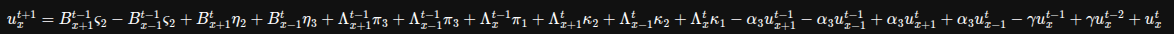

In [57]:
max_dx=4
max_dt=4
max_total=4
expr = sp.expand(residual)
poly = sp.Poly(expr, dx, dt, domain='EX')  # keep symbolic coeffs
kept = sp.S(0)

for (px, pt), coeff in poly.terms():
    if (px <= max_dx) and (pt <= max_dt) and ((px + pt) <= max_total):
        kept += coeff * dx**px * dt**pt

In [58]:
kept

Delta_t**4*(-5*s_1*s_2*Derivative(u(x, t), (t, 4))/8 + 7*s_1*Derivative(u(x, t), (t, 4))/12 + 7*s_2*Derivative(u(x, t), (t, 4))/12 - Derivative(u(x, t), (t, 4))/2) + Delta_t**3*Delta_x*(-s_1*s_2*Derivative(B(x, t), (t, 3), x)/6 + s_1*Derivative(B(x, t), (t, 3), x)/6) + Delta_t**3*(7*s_1*s_2*Derivative(u(x, t), (t, 3))/6 - s_1*Derivative(u(x, t), (t, 3)) - s_2*Derivative(u(x, t), (t, 3)) + Derivative(u(x, t), (t, 3))) + Delta_t**2*Delta_x**2*(s_1*s_2*Derivative(\Lambda(x, t), (t, 2), (x, 2))/4 - s_1*Derivative(u(x, t), (t, 2), (x, 2))/4 - s_2*Derivative(\Lambda(x, t), (t, 2), (x, 2))/4 - s_2*Derivative(u(x, t), (t, 2), (x, 2))/4 + Derivative(u(x, t), (t, 2), (x, 2))/2) + Delta_t**2*Delta_x*(s_1*s_2*Derivative(B(x, t), (t, 2), x)/2 - s_1*Derivative(B(x, t), (t, 2), x)/2) + Delta_t**2*(-3*s_1*s_2*Derivative(u(x, t), (t, 2))/2 + s_1*Derivative(u(x, t), (t, 2)) + s_2*Derivative(u(x, t), (t, 2))) + Delta_t*Delta_x**3*(-s_1*s_2*Derivative(B(x, t), t, (x, 3))/6 + s_1*Derivative(B(x, t), t, (x,

In [59]:
term1u = sp.simplify(sp.expand(kept)).subs({UF.diff(t, 4):dut4,UF.diff(x,t, 3):duxt3,UF.diff(t, 3):dut3,UF.diff(x, 2, t, 2):dux2t2,UF.diff(x, t, 2):duxt2,
                                UF.diff(t, 2):dut2,UF.diff(x,3,t):dux3t,UF.diff(x,2,t):dux2t,UF.diff(x,t):duxt,
                                UF.diff(t):dut,UF.diff(x,4):dux4,UF.diff(x,3):dux3,UF.diff(x,2):dux2,UF.diff(x):dux})
term1B = term1u.subs({BF.diff(t, 4):dBt4,BF.diff(x,t, 3):dBxt3,BF.diff(t, 3):dBt3,BF.diff(x, 2, t, 2):dBx2t2,BF.diff(x, t, 2):dBxt2,
                                BF.diff(t, 2):dBt2,BF.diff(x,3,t):dBx3t,BF.diff(x,2,t):dBx2t,BF.diff(x,t):dBxt,
                                BF.diff(t):dBt,BF.diff(x,4):dBx4,BF.diff(x,3):dBx3,BF.diff(x,2):dBx2,BF.diff(x):dBx})
term1 = term1B.subs({LF.diff(t, 4):dLat4,LF.diff(x,t, 3):dLaxt3,LF.diff(t, 3):dLat3,LF.diff(x, 2, t, 2):dLax2t2,LF.diff(x, t, 2):dLaxt2,
                                LF.diff(t, 2):dLat2,LF.diff(x,3,t):dLax3t,LF.diff(x,2,t):dLax2t,LF.diff(x,t):dLaxt,
                                LF.diff(t):dLat,LF.diff(x,4):dLax4,LF.diff(x,3):dLax3,LF.diff(x,2):dLax2,LF.diff(x):dLax})
display(term1)

-5*Delta_t**4*\frac{\partial^{4}{u}}{\partial{t^{4}}}*s_1*s_2/8 + 7*Delta_t**4*\frac{\partial^{4}{u}}{\partial{t^{4}}}*s_1/12 + 7*Delta_t**4*\frac{\partial^{4}{u}}{\partial{t^{4}}}*s_2/12 - Delta_t**4*\frac{\partial^{4}{u}}{\partial{t^{4}}}/2 - Delta_t**3*Delta_x*\frac{\partial^{4}{B}}{\partial{x}\partial{t^{3}}}*s_1*s_2/6 + Delta_t**3*Delta_x*\frac{\partial^{4}{B}}{\partial{x}\partial{t^{3}}}*s_1/6 + 7*Delta_t**3*\frac{\partial^{3}{u}}{\partial{t^{3}}}*s_1*s_2/6 - Delta_t**3*\frac{\partial^{3}{u}}{\partial{t^{3}}}*s_1 - Delta_t**3*\frac{\partial^{3}{u}}{\partial{t^{3}}}*s_2 + Delta_t**3*\frac{\partial^{3}{u}}{\partial{t^{3}}} + Delta_t**2*Delta_x**2*\frac{\partial^{4}{\Lambda}}{\partial{x^{2}}\partial{t^{2}}}*s_1*s_2/4 - Delta_t**2*Delta_x**2*\frac{\partial^{4}{\Lambda}}{\partial{x^{2}}\partial{t^{2}}}*s_2/4 - Delta_t**2*Delta_x**2*\frac{\partial^{4}{u}}{\partial{x^{2}}\partial{t^{2}}}*s_1/4 - Delta_t**2*Delta_x**2*\frac{\partial^{4}{u}}{\partial{x^{2}}\partial{t^{2}}}*s_2/4 + Delta_t

In [60]:
# term1 = sp.expand(kept).subs({UF.diff(x, 4):dux4,UF.diff(x, 3):dux3,UF.diff(x, 2, t, 2):dux2t2,UF.diff(x, t, 2):duxt2,
#                               UF.diff(x,2,t):dux2t,UF.diff(t, 2):dut2,UF.diff(x,2):dux2,UF.diff(x):dux,UF.diff(t):dut,
#                              BF.diff(x, 4):dBx4,BF.diff(x, 3,t):dBx3t,BF.diff(x, 3):dBx3,BF.diff(x, 2, t, 2):dBx2t2,BF.diff(x, t, 2):dBxt2,
#                              BF.diff(x,2,t):dux2t,BF.diff(x,t):duxt,BF.diff(t, 2):dBt2,BF.diff(x,2):dBx2,BF.diff(x):dBx})
# display(term1)

In [61]:
term2 = sp.collect(expand(-term1/(dt*s1*s2)+dut),[dut,dux,dux2,duxt,dut2,dux2t,duxt2,dux3,dut3,dux2t2,dux4,dut4
                                                  ,dBx3t,dBxt2,dBxt3,dLax2,dLax2t,dLax2t2,dLax4])
# display(term2)
brokeq2(term2, terms_per_line=2)

<IPython.core.display.Math object>

$$
 \displaystyle\frac{\partial u}{\partial t} = -\displaystyle\frac{\partial B}{\partial x} ,
$$

$$
 \displaystyle\frac{\partial^{2} u}{\partial t \partial x} = -\displaystyle\frac{\partial^{2} B}{\partial x^{2}} ,
$$

$$
 \displaystyle\frac{\partial^{2} u}{\partial t^{2}} = - \displaystyle\frac{\partial^{2} B}{\partial x \partial t} = \displaystyle\frac{\partial }{\partial x}\left(B_{u} \frac{\partial B}{\partial x}\right) ,
$$

$$
\displaystyle\frac{\partial^{4} B}{\partial x^{3} \partial t} = -\displaystyle\frac{\partial^{4} u}{\partial x^{2} \partial t^{2}} = -\displaystyle\frac{\partial }{\partial x^{3}}\left(B_{u} \frac{\partial B}{\partial x}\right) ,
$$
$$
\displaystyle\frac{\partial^{4} B}{\partial x^{2} \partial t^{2}} = -\displaystyle\frac{\partial^{3} }{\partial x^{2} \partial t}\left(B_{u} \frac{\partial B}{\partial x}\right) = -\displaystyle\frac{\partial^{2} }{\partial x^{2} }\left( \frac{\partial B_{u}}{\partial t} \frac{\partial B}{\partial x} + B_{u} \frac{\partial}{\partial x }\left(-B_{u} \frac{\partial B}{\partial x} \right) \right) = \displaystyle\frac{\partial^{2} }{\partial x^{2} }\left( B_{uu} \left(\frac{\partial B}{\partial x}\right)^{2} - \frac{1}{2}\frac{\partial B_{u}^{2}}{\partial x }  \frac{\partial B}{\partial x}  + B_{u}^{2} \frac{\partial^{2} B}{\partial x^{2}} \right) ,
$$

In [62]:
Bu = sp.Symbol('B_{u}')
dBuBx = sp.Symbol('\\frac{\partial}{\partial{x}}\\left(B_{u}\\frac{\partial{B}}{\partial{x}}\\right)')
dBuBx3 = sp.Symbol('\\frac{\partial^{3}}{\partial{x}^{3}}\\left(B_{u}\\frac{\partial{B}}{\partial{x}}\\right)')
term3 = sp.collect(sp.expand(term2
                            .subs(dux2t,-dBx3*dx/dt)
                             .subs(duxt,-dBx2*dx/dt)
                             .subs(dut2,-dBxt*dx/dt)
                            .subs(dut3,-dBxt2*dx/dt) 
                            .subs(dut4,-dBxt3*dx/dt)
                            .subs(dux2t2,-dBx3t*dx/dt)
                            # .subs(dBx3t,-dBuBx3*dx/dt)
                            ) 
                   ,[dut,dux,dux2,duxt,dut2,dux2t,duxt2,dux3,dut3,dux2t2,dux4,
                     dBxt,dBx3t,dBx3,dBxt2,dBxt3,dBx2 ,dLax2,dLax2t,dLax2t2,dLax4])
# display(term3)
brokeq2(term3, terms_per_line=1)

<IPython.core.display.Math object>

In [67]:
term4 = sp.collect(sp.expand(term3
                            .subs(dLax2,-dBxt*dt/dx)
                            .subs(dLax2t,-dBxt2*dt/dx)
                            .subs(dLax2t2,-dBxt3*dt/dx)
                            .subs(dLax4,-dBx3t*dt/dx)
                            ) 
                   ,[dut,dux,dux2,duxt,dut2,dux2t,duxt2,dux3,dut3,dux2t2,dux4,
                     dBxt,dBx3t,dBx3,dBxt2,dBxt3,dBx2 ,dLax2,dLax2t,dLax2t2,dLax4])
brokeq2(term4, terms_per_line=1)

<IPython.core.display.Math object>

## Benchmarks
For the nonlinear convection equation

\\[ \boxed{ \frac{\partial u}{\partial t} +\frac{\partial F(u)}{\partial x}=0, \qquad F(u)=cu^2, } \\]

where \\(c\\) is a constant, we can derive an exact analytical solution with periodic boundary conditions using the method of characteristics.

### Governing equation

Expanding the flux derivative gives

\\[ \boxed{ \frac{\partial u}{\partial t} +2cu\frac{\partial u}{\partial x}=0. } \\]

Consider the periodic domain

\\[ x\in[0,L),\qquad u(x+L,t)=u(x,t), \\]

with the initial condition

\\[ \boxed{ u(x,0)=u_m+A\sin(kx), \qquad k=\frac{2\pi m}{L}. } \\]

Here, \\(u_m\\) is the mean value, \\(A>0\\) is the amplitude, and \\(m\\) is the number of wavelengths.

### Analytical solution using characteristics

Along a characteristic \\(x=x(t)\\),

\\[ \frac{du}{dt} =\frac{\partial u}{\partial t} +\frac{dx}{dt}\frac{\partial u}{\partial x}. \\]

Choosing

\\[ \frac{dx}{dt}=2cu \\]

and substituting into the governing equation gives

\\[ \frac{du}{dt}=0. \\]

Therefore, \\(u\\) remains constant along each characteristic.

Let \\(\xi\\) denote its initial position. We obtain

\\[ u(x(t),t)=u_m+A\sin(k\xi). \\]

Integrating the characteristic velocity,

\\[ \boxed{ x=\xi+2ct[u_m+A\sin(k\xi)]. } \\]

Since

\\[ \xi=x-2ctu(x,t), \\]

the exact implicit analytical solution is

\\[ \boxed{ u(x,t)=u_m+A\sin\left(k[x-2ctu(x,t)]\right). } \\]

This solution satisfies the nonlinear convection equation exactly, provided the characteristics have not intersected.

### Shock formation time

Differentiating the characteristic position with respect to \\(\xi\\),

\\[ \frac{\partial x}{\partial \xi} =1+2cAkt\cos(k\xi). \\]

The first shock forms when this derivative reaches zero. Thus, for \\(c\ne0\\),

\\[ \boxed{ t_s=\frac{1}{2|c|Ak} =\frac{L}{4\pi m|c|A}. } \\]

For \\(c=0\\), the initial condition remains stationary and no shock forms.

### Numerical example

Choose the following parameters:

| Parameter                     | Value      |
| ----------------------------- | ---------- |
| Domain length \\(L\\)         | \\(2\pi\\) |
| Mean value \\(u_m\\)          | \\(1.0\\)  |
| Amplitude \\(A\\)             | \\(0.2\\)  |
| Nonlinear coefficient \\(c\\) | \\(0.5\\)  |
| Wave number \\(k\\)           | \\(1\\)    |
| Shock time \\(t_s\\)          | \\(5.0\\)  |

For these parameters, the equation reduces to the classical inviscid Burgers equation, since \\(2c=1\\).

The solution is

\\[ u(x,t)=1+0.2\sin[x-tu(x,t)]. \\]

### General analytical solution for any initial condition

More generally, for

\\[ \frac{\partial u}{\partial t} +2cu\frac{\partial u}{\partial x}=0, \qquad u(x,0)=u_0(x), \\]

the method of characteristics gives

\\[ \boxed{ \begin{aligned} u(x,t)&=u_0(\xi),\\\ x&=\xi+2ctu_0(\xi). \end{aligned} } \\]

Equivalently,

\\[ \boxed{ u(x,t)=u_0\left(x-2ctu(x,t)\right). } \\]

For a smooth periodic initial condition, this is valid before shock formation.

#### Important for your MRT-LBM study

For a fourth-order accuracy investigation, I recommend using \\(c=0.5\\), \\(A=0.2\\), \\(L=2\pi\\), and testing at \\(t=1\\) or \\(t=2\\). You can then vary \\(c\\) independently to investigate the effect of nonlinear convection strength on the numerical accuracy and stability.

The key distinction from linear advection is that the local characteristic velocity is \\(2cu\\), not \\(c\\). Therefore, the wave does not simply translate: it progressively deforms, even before shock formation.

In [9]:
# import numpy as np
# import matplotlib.pyplot as plt
# # Parameters
# L = 2.0 * np.pi
# Nx = 400
# m = 1
# um = 1.0
# A = 0.2
# c = 0.5
# k = 2.0 * np.pi * m / L
# ts = np.inf if c == 0 else 1.0 / (2.0 * abs(c) * A * k)
# # Periodic spatial grid
# x = np.arange(Nx) * L / Nx
# def analytical_solution(x, t, um, A, c, k, tol=1e-13, max_iter=100):
#     if t < 0 or t >= ts:
#         raise ValueError("Time must satisfy 0 <= t < ts")
#     # Initial guess based on mean advection velocity
#     u = um + A * np.sin(k * (x - 2.0*c*um*t))
#     for _ in range(max_iter):
#         phase = k * (x - 2.0*c*t*u)
#         G = u - um - A*np.sin(phase)
#         dG = 1.0 + 2.0*c*A*k*t*np.cos(phase)
#         du = G / dG
#         u -= du
#         if np.max(np.abs(du)) < tol:
#             return u
#     raise RuntimeError("Newton iteration did not converge")
# # Plot
# times = [0.0, 1.0, 2.0, 3.0, 4.0]
# plt.figure(figsize=(8, 5))
# for t in times:
#     u = analytical_solution(x, t, um, A, c, k)
#     plt.plot(x, u, label=fr"$t={t}$")

# plt.xlabel("$x$")
# plt.ylabel("$u(x,t)$")
# plt.title(r"Nonlinear convection: $F(u)=cu^2$")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()

# print(f"Shock formation time: {ts:.6f}")

Domain length: 1.0
Wave number: 6.28318531
Shock formation time: 6.36619772

Case 1: Nx=10
dx=1.000000e-01, dt=1.000000e-01, nt=40
ce=1.250000e-02
L2 error   = 9.32562413e-01
Linf error = 9.41574650e-01

Case 2: Nx=20
dx=5.000000e-02, dt=5.000000e-02, nt=80
ce=1.250000e-02
L2 error   = 7.48075416e-01
Linf error = 7.89872168e-01

Case 3: Nx=40
dx=2.500000e-02, dt=2.500000e-02, nt=160
ce=1.250000e-02
L2 error   = 5.15330290e-01
Linf error = 5.87470544e-01

Case 4: Nx=80
dx=1.250000e-02, dt=1.250000e-02, nt=320
ce=1.250000e-02
L2 error   = 3.20879427e-01
Linf error = 4.06020194e-01

Case 5: Nx=160
dx=6.250000e-03, dt=6.250000e-03, nt=640
ce=1.250000e-02
L2 error   = 1.86753438e-01
Linf error = 2.58846432e-01

Case 6: Nx=320
dx=3.125000e-03, dt=3.125000e-03, nt=1280
ce=1.250000e-02
L2 error   = 1.03400535e-01
Linf error = 1.54027027e-01

Convergence analysis
-----------------------------------------------------------------
Nx=  20, L2=7.48075416e-01, order=0.3180
Nx=  40, L2=5.15330290e-01

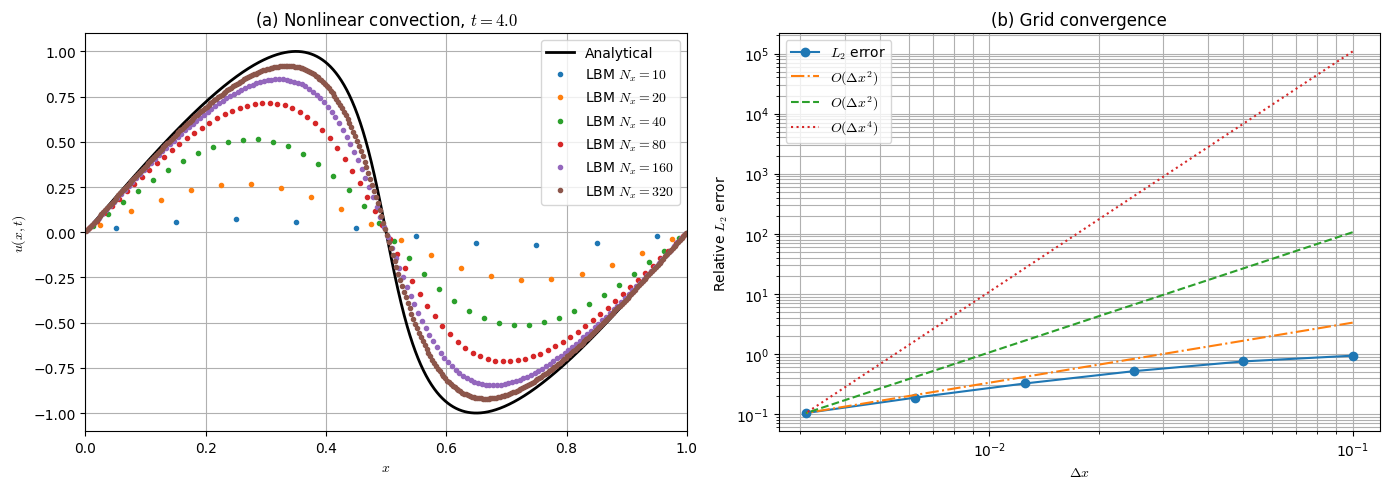

In [29]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'cm'
#-------------------- Parameters (physical units) --------------------
A       = 1.0
um      = 0.0
phi     = 0.0
c       = 0.0125
L       = 1.0
m_waves = 1
k_w     = 2.0*np.pi*m_waves/L
t_end   = 4.0
#-------------------- Shock formation time --------------------
t_shock = (np.inf if c == 0 else 1.0/(2.0*abs(c)*A*k_w) )
print(f"Domain length: {L}")
print(f"Wave number: {k_w:.8f}")
print(f"Shock formation time: {t_shock:.8f}")
if t_end >= t_shock:
    raise ValueError("Final time must be before shock formation.")
#-------------------- Lattice D1Q3 --------------------
w = np.array([4.0/6.0, 1.0/6.0, 1.0/6.0],dtype="float64")
cx = np.array([0, 1, -1], dtype="int16")
cs = 1.0/np.sqrt(3.0)
cs2 = cs**2
#-------------------- Grid refinement --------------------
Nx0 = np.array([10, 20, 40, 80, 160, 320], dtype="int64")
# Constant dx/dt ratio: dt proportional to dx
r0 = np.full(len(Nx0), 1.0)
cases = len(Nx0)
u_cases = np.empty(cases, dtype=object)
u_exact_cases = np.empty(cases, dtype=object)
errors_L2 = np.zeros(cases)
errors_Linf = np.zeros(cases)
#-------------------- Analytical solution --------------------
def analytical_solution(x, t, um, A, c, k, phi=0.0, tol=1e-13, max_iter=100):
    u = um + A*np.sin(k*(x - 2.0*c*um*t) + phi)
    for iteration in range(max_iter):
        phase = k*(x - 2.0*c*t*u) + phi
        G = u - um - A*np.sin(phase)
        dG = 1.0 + 2.0*c*A*k*t*np.cos(phase)
        du = G/dG
        u -= du
        if np.max(np.abs(du)) < tol:
            return u
    raise RuntimeError("Analytical solution did not converge")
#========================== Main cases ==========================
for case in range(cases):
    #-------------------- Numerical parameters --------------------
    Nx = Nx0[case]
    dx = L/Nx
    # Cell-centered periodic grid
    x = (np.arange(Nx) + 0.5)*dx
    r_target = r0[case]
    dt_target = dx/r_target
    # Finish exactly at t_end
    nt = int(np.ceil(t_end/dt_target))
    dt = t_end/nt
    r = dx/dt
    # Nonlinear flux coefficient in lattice units
    ce = c/r
    print(f"\nCase {case+1}: Nx={Nx}")
    print(f"dx={dx:.6e}, dt={dt:.6e}, nt={nt}")
    print(f"ce={ce:.6e}")
    #-------------------- Initial condition --------------------
    u = um + A*np.sin(k_w*x + phi)
    #-------------------- Distribution arrays --------------------
    f   = np.zeros((3, Nx), dtype="float64")
    feq = np.zeros((3, Nx), dtype="float64")
    fp  = np.zeros((3, Nx), dtype="float64")
    #-------------------- Initialize equilibrium --------------------
    F = ce*u**2
    for k in range(3):
        f[k, :] = w[k]*(u + cx[k]*F/cs2)
    #========================== Time loop ==========================
    for t in range(nt):
        #-------------------- Macroscopic field --------------------
        u = np.sum(f, axis=0)
        #-------------------- Nonlinear equilibrium --------------------
        F = ce*u**2
        for k in range(3):
            feq[k, :] = w[k]*(u + cx[k]*F/cs2)
        #-------------------- Full equilibrium collision --------------------
        fp[:, :] = feq[:, :]
        #-------------------- Periodic streaming --------------------
        for k in range(3):
            f[k, :] = np.roll(fp[k, :], cx[k])
        if not np.all(np.isfinite(f)):
            raise FloatingPointError(f"Non-finite distribution in case {case+1}, step {t}")
    #-------------------- Final macroscopic field --------------------
    u = np.sum(f, axis=0)
    #-------------------- Analytical solution --------------------
    u_exact = analytical_solution(x, t_end, um, A, c, k_w, phi)
    #-------------------- Save fields --------------------
    u_cases[case] = u.copy()
    u_exact_cases[case] = u_exact.copy()
    #-------------------- Errors --------------------
    errors_L2[case] = np.sqrt(np.sum((u-u_exact)**2) / np.sum(u_exact**2))
    errors_Linf[case] = np.max(np.abs(u-u_exact))
    print(f"L2 error   = {errors_L2[case]:.8e}")
    print(f"Linf error = {errors_Linf[case]:.8e}")
#========================== Convergence ==========================
print("\nConvergence analysis")
print("-"*65)
for case in range(1, cases):
    order = np.log(errors_L2[case-1]/errors_L2[case])/np.log(Nx0[case]/Nx0[case-1])
    print(f"Nx={Nx0[case]:4d}, "f"L2={errors_L2[case]:.8e}, "f"order={order:.4f}")
#========================== Side-by-side plots ==========================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
#-------------------------- (a) Numerical solutions --------------------------
x_exact = np.linspace(0, L, 2000, endpoint=False)
u_exact = analytical_solution(x_exact, t_end, um, A, c, k_w, phi)
ax[0].plot(x_exact, u_exact,'k-', lw=2,label="Analytical")
for case in range(cases):
    Nx = Nx0[case]
    dx = L/Nx
    x = (np.arange(Nx) + 0.5)*dx
    ax[0].plot(x, u_cases[case],marker='o',linestyle='none',markersize=3,label=fr"LBM $N_x={Nx}$")
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$u(x,t)$")
ax[0].set_title(fr"(a) Nonlinear convection, $t={t_end}$")
ax[0].set_xlim(0, L)
ax[0].legend()
ax[0].grid(True)
#-------------------------- (b) Convergence analysis --------------------------
h = L/Nx0
ax[1].loglog(h, errors_L2,'o-', label=r"$L_2$ error")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**1,'-.', label=r"$O(\Delta x^2)$")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**2,'--', label=r"$O(\Delta x^2)$")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**4, ':', label=r"$O(\Delta x^4)$" )
ax[1].set_xlabel(r"$\Delta x$")
ax[1].set_ylabel(r"Relative $L_2$ error")
ax[1].set_title("(b) Grid convergence")
ax[1].legend()
ax[1].grid(True, which='both')
#-------------------------- Layout --------------------------
plt.tight_layout()
plt.show()


Domain length: 1.0
Wave number: 6.28318531
Shock formation time: 6.36619772

Case 1: Nx=10
dx=1.000000e-01, dt=8.000000e-01, nt=5
ce=1.000000e-01
L2 error   = 3.34408163e-01
Linf error = 3.77573573e-01

Case 2: Nx=20
dx=5.000000e-02, dt=2.000000e-01, nt=20
ce=5.000000e-02
L2 error   = 3.21741222e-01
Linf error = 4.08085198e-01

Case 3: Nx=40
dx=2.500000e-02, dt=5.000000e-02, nt=80
ce=2.500000e-02
L2 error   = 3.20972768e-01
Linf error = 4.05084875e-01

Case 4: Nx=80
dx=1.250000e-02, dt=1.250000e-02, nt=320
ce=1.250000e-02
L2 error   = 3.20879427e-01
Linf error = 4.06020194e-01

Convergence analysis
-----------------------------------------------------------------
Nx=  20, L2=3.21741222e-01, order=0.0557
Nx=  40, L2=3.20972768e-01, order=0.0034
Nx=  80, L2=3.20879427e-01, order=0.0004


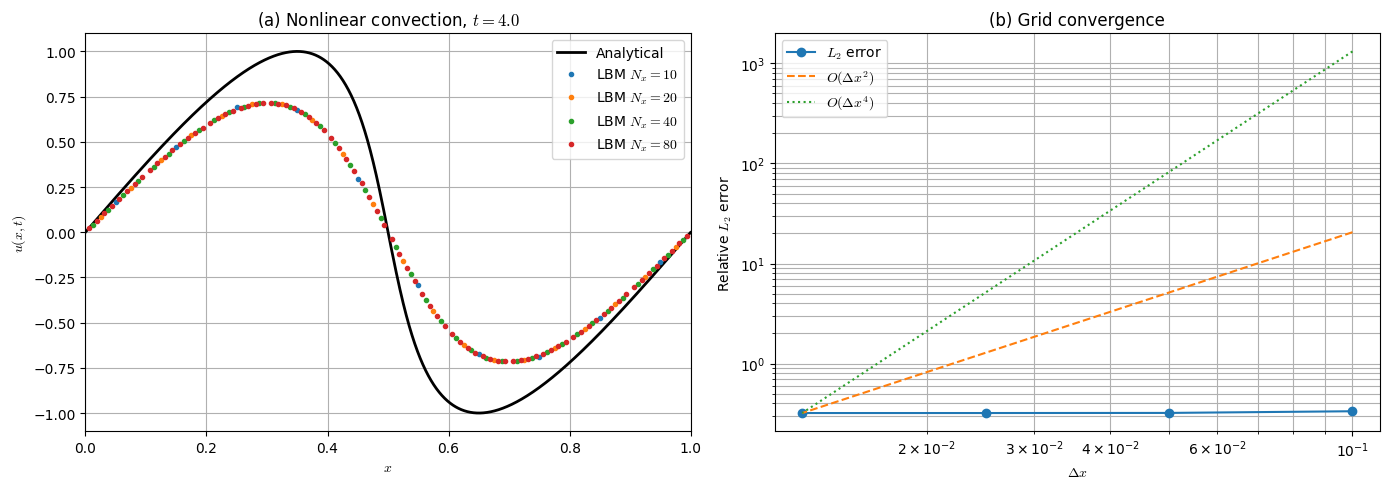

In [27]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'cm'
#-------------------- Parameters (physical units) --------------------
A       = 1.0
um      = 0.0
phi     = 0.0
c       = 0.0125
L       = 1.0
m_waves = 1
k_w     = 2.0*np.pi*m_waves/L
t_end   = 4.0
#-------------------- Shock formation time --------------------
t_shock = (np.inf if c == 0 else 1.0/(2.0*abs(c)*A*k_w) )
print(f"Domain length: {L}")
print(f"Wave number: {k_w:.8f}")
print(f"Shock formation time: {t_shock:.8f}")
if t_end >= t_shock:
    raise ValueError("Final time must be before shock formation.")
#-------------------- Lattice D1Q3 --------------------
w = np.array([4.0/6.0, 1.0/6.0, 1.0/6.0],dtype="float64")
cx = np.array([0, 1, -1], dtype="int16")
cs = 1.0/np.sqrt(3.0)
cs2 = cs**2
#-------------------- Grid refinement --------------------
Nx0 = np.array([10, 20, 40, 80], dtype="int64")
# r0  = np.array([1.0, 2.0, 4.0, 8.0])
r0  = np.array([0.125, 0.25, 0.5, 1.0])
cases = len(Nx0)
u_cases = np.empty(cases, dtype=object)
u_exact_cases = np.empty(cases, dtype=object)
errors_L2 = np.zeros(cases)
errors_Linf = np.zeros(cases)
#-------------------- Analytical solution --------------------
def analytical_solution(x, t, um, A, c, k, phi=0.0, tol=1e-13, max_iter=100):
    # Initial guess
    u = um + A*np.sin(k*(x - 2.0*c*um*t) + phi)
    for iteration in range(max_iter):
        phase = k*(x - 2.0*c*t*u) + phi
        G = u - um - A*np.sin(phase)
        dG = 1.0 + 2.0*c*A*k*t*np.cos(phase)
        du = G/dG
        u -= du
        if np.max(np.abs(du)) < tol:
            return u
    raise RuntimeError("Analytical solution did not converge")
#========================== Main cases ==========================
for case in range(cases):
    #-------------------- Numerical parameters --------------------
    Nx = Nx0[case]
    dx = L/Nx
    x = (np.arange(Nx) + 0.5)*dx  # Cell-centered periodic grid
    r_target = r0[case]
    dt_target = dx/r_target
    nt = int(np.ceil(t_end/dt_target)) # Finish exactly at t_end
    dt = t_end/nt
    r = dx/dt
    ce = c/r # Nonlinear flux coefficient in lattice units
    #-------------------- Relaxation parameters --------------------
    tau1 = 0.5
    om1 = 1.0/tau1
    print(f"\nCase {case+1}: Nx={Nx}")
    print(f"dx={dx:.6e}, dt={dt:.6e}, nt={nt}")
    print(f"ce={ce:.6e}")
    #-------------------- Initial condition --------------------
    u = um + A*np.sin(k_w*x + phi)
    #-------------------- Distribution arrays --------------------
    f   = np.zeros((3, Nx), dtype="float64")
    feq = np.zeros((3, Nx), dtype="float64")
    fp  = np.zeros((3, Nx), dtype="float64")
    #-------------------- Initialize equilibrium --------------------
    F = ce*u**2
    for k in range(3):
        f[k, :] = w[k]*(u+ cx[k]*F/cs2 )
    #========================== Time loop ==========================
    for t in range(nt):
        #-------------------- Macroscopic field --------------------
        u = np.sum(f, axis=0)
        #-------------------- Equilibrium --------------------
        F = ce*u**2
        for k in range(3):
            feq[k, :] = w[k]*(u + cx[k]*F/cs2 )
        #-------------------- Non-equilibrium moments --------------------
        df = f-feq
        mx = np.einsum('i,ix->x', cx, df)
        #-------------------- MRT collision --------------------
        for k in range(3):
            # fp[k, :] = (feq[k, :]+ w[k]*((1.0-om1)*cx[k]*mx/cs2 ))
            fp[k, :] = (feq[k, :] )
        #-------------------- Periodic streaming --------------------
        for k in range(3):
            f[k, :] = np.roll(fp[k, :], cx[k])
        if not np.all(np.isfinite(f)):
            raise FloatingPointError(f"Non-finite distribution in case {case+1}, step {t}")
    #-------------------- Final macroscopic field --------------------
    u = np.sum(f, axis=0)
    #-------------------- Analytical solution --------------------
    u_exact = analytical_solution(x, t_end, um, A, c, k_w, phi)
    #-------------------- Save fields --------------------
    u_cases[case] = u.copy()
    u_exact_cases[case] = u_exact.copy()
    #-------------------- Errors --------------------
    errors_L2[case] = np.sqrt(np.sum((u-u_exact)**2) / np.sum(u_exact**2) )
    errors_Linf[case] = np.max(np.abs(u-u_exact))
    print(f"L2 error   = {errors_L2[case]:.8e}")
    print(f"Linf error = {errors_Linf[case]:.8e}")
#========================== Convergence ==========================
print("\nConvergence analysis")
print("-"*65)
for case in range(1, cases):
    order = np.log(errors_L2[case-1]/errors_L2[case])/np.log(Nx0[case]/Nx0[case-1])
    print(f"Nx={Nx0[case]:4d}, "f"L2={errors_L2[case]:.8e}, "f"order={order:.4f}")
#========================== Side-by-side plots ==========================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
#-------------------------- (a) Numerical solutions --------------------------
x_exact = np.linspace(0, L, 2000, endpoint=False)
u_exact = analytical_solution(x_exact, t_end, um, A, c, k_w, phi)
ax[0].plot(x_exact, u_exact, 'k-', lw=2, label="Analytical")
for case in range(cases):
    Nx = Nx0[case]
    dx = L / Nx
    x = (np.arange(Nx) + 0.5) * dx
    ax[0].plot(x, u_cases[case],marker='o',linestyle='none',markersize=3,label=fr"LBM $N_x={Nx}$")
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$u(x,t)$")
ax[0].set_title(fr"(a) Nonlinear convection, $t={t_end}$")
ax[0].set_xlim(0, L)
ax[0].legend()
ax[0].grid(True)
#-------------------------- (b) Convergence analysis --------------------------
h = L / Nx0
ax[1].loglog(h, errors_L2, 'o-', label=r"$L_2$ error")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**2,'--', label=r"$O(\Delta x^2)$")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**4,':', label=r"$O(\Delta x^4)$")
ax[1].set_xlabel(r"$\Delta x$")
ax[1].set_ylabel(r"Relative $L_2$ error")
ax[1].set_title("(b) Grid convergence")
ax[1].legend()
ax[1].grid(True, which='both')
#-------------------------- Layout --------------------------
plt.tight_layout()
plt.show()

Domain length: 1.0
Wave number: 6.28318531
Shock formation time: 6.36619772

Case 1: Nx=10
dx=1.000000e-01, dt=5.000000e-02, nt=80
ce=6.250000e-03
tau1=0.500000, tau2=0.625000
L2 error   = 8.04864633e-02
Linf error = 1.22478511e-01

Case 2: Nx=20
dx=5.000000e-02, dt=1.250000e-02, nt=320
ce=3.125000e-03
tau1=0.500000, tau2=0.625000
L2 error   = 1.39432486e-02
Linf error = 2.68139291e-02

Case 3: Nx=40
dx=2.500000e-02, dt=3.125000e-03, nt=1280
ce=1.562500e-03
tau1=0.500000, tau2=0.625000
L2 error   = 2.32211652e-03
Linf error = 2.99201338e-03

Case 4: Nx=80
dx=1.250000e-02, dt=7.812500e-04, nt=5120
ce=7.812500e-04
tau1=0.500000, tau2=0.625000
L2 error   = 5.49495064e-04
Linf error = 6.51201757e-04

Convergence analysis
-----------------------------------------------------------------
Nx=  20, L2=1.39432486e-02, order=2.5292
Nx=  40, L2=2.32211652e-03, order=2.5861
Nx=  80, L2=5.49495064e-04, order=2.0793


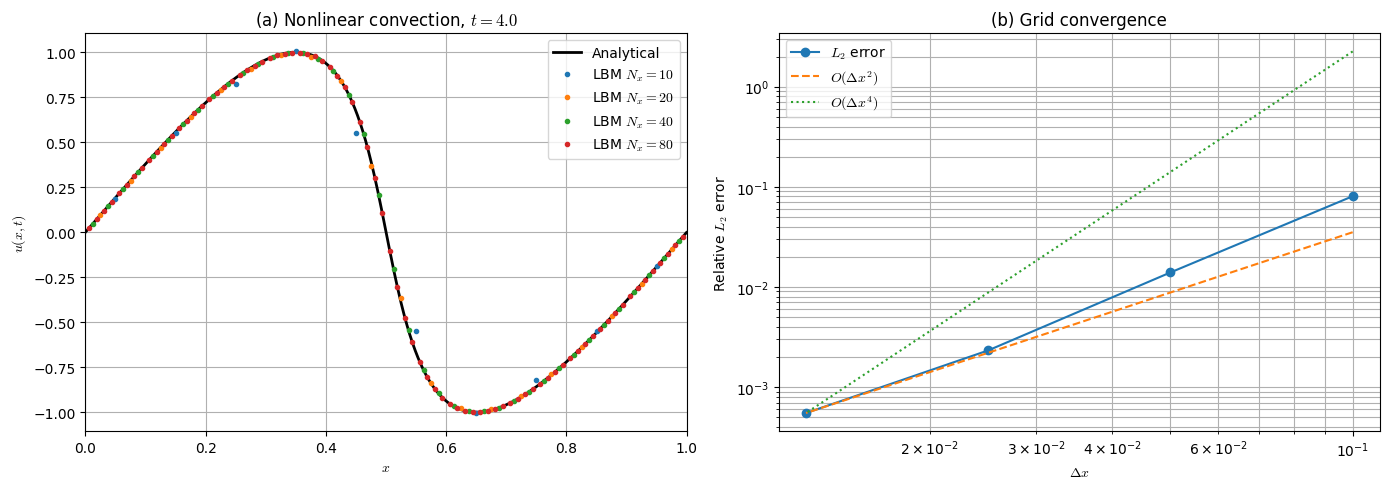

In [32]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'cm'
#-------------------- Parameters (physical units) --------------------
A       = 1.0
um      = 0.0
phi     = 0.0
c       = 0.0125
L       = 1.0
m_waves = 1
k_w     = 2.0*np.pi*m_waves/L
t_end   = 4.0
#-------------------- Shock formation time --------------------
t_shock = (np.inf if c == 0 else 1.0/(2.0*abs(c)*A*k_w) )
print(f"Domain length: {L}")
print(f"Wave number: {k_w:.8f}")
print(f"Shock formation time: {t_shock:.8f}")
if t_end >= t_shock:
    raise ValueError("Final time must be before shock formation.")
#-------------------- Lattice D1Q3 --------------------
w = np.array([4.0/6.0, 1.0/6.0, 1.0/6.0],dtype="float64")
cx = np.array([0, 1, -1], dtype="int16")
cs = 1.0/np.sqrt(3.0)
cs2 = cs**2
#-------------------- Grid refinement --------------------
Nx0 = np.array([10, 20, 40, 80], dtype="int64")
r0  = np.array([2.0, 4.0, 8.0, 16.0])
cases = len(Nx0)
u_cases = np.empty(cases, dtype=object)
u_exact_cases = np.empty(cases, dtype=object)
errors_L2 = np.zeros(cases)
errors_Linf = np.zeros(cases)
#-------------------- Analytical solution --------------------
def analytical_solution(x, t, um, A, c, k, phi=0.0, tol=1e-13, max_iter=100):
    """
    Exact smooth solution of:
        du/dt + d(c*u**2)/dx = 0
    Periodic initial condition:
        u(x,0) = um + A*sin(k*x + phi)
    Valid before shock formation.
    """
    # Initial guess
    u = um + A*np.sin(k*(x - 2.0*c*um*t) + phi)
    for iteration in range(max_iter):
        phase = k*(x - 2.0*c*t*u) + phi
        G = u - um - A*np.sin(phase)
        dG = 1.0 + 2.0*c*A*k*t*np.cos(phase)
        du = G/dG
        u -= du
        if np.max(np.abs(du)) < tol:
            return u
    raise RuntimeError("Analytical solution did not converge")
#========================== Main cases ==========================
for case in range(cases):
    #-------------------- Numerical parameters --------------------
    Nx = Nx0[case]
    dx = L/Nx
    x = (np.arange(Nx) + 0.5)*dx  # Cell-centered periodic grid
    r_target = r0[case]
    dt_target = dx/r_target
    nt = int(np.ceil(t_end/dt_target)) # Finish exactly at t_end
    dt = t_end/nt
    r = dx/dt
    ce = c/r # Nonlinear flux coefficient in lattice units
    #-------------------- Relaxation parameters --------------------
    tau1 = 0.5
    om1 = 1.0/tau1
    om2 = 1.6
    tau2 = 1.0/om2
    print(f"\nCase {case+1}: Nx={Nx}")
    print(f"dx={dx:.6e}, dt={dt:.6e}, nt={nt}")
    print(f"ce={ce:.6e}")
    print(f"tau1={tau1:.6f}, tau2={tau2:.6f}")
    #-------------------- Initial condition --------------------
    u = um + A*np.sin(k_w*x + phi)
    #-------------------- Distribution arrays --------------------
    f   = np.zeros((3, Nx), dtype="float64")
    feq = np.zeros((3, Nx), dtype="float64")
    fp  = np.zeros((3, Nx), dtype="float64")
    #-------------------- Initialize equilibrium --------------------
    F = ce*u**2
    Q = ce**2*u**3
    for k in range(3):
        f[k, :] = w[k]*(u+ cx[k]*F/cs2 + (cx[k]**2-cs2)*Q/(2.0*cs2**2))
    #========================== Time loop ==========================
    for t in range(nt):
        #-------------------- Macroscopic field --------------------
        u = np.sum(f, axis=0)
        #-------------------- Equilibrium --------------------
        F = ce*u**2
        Q = ce**2*u**3
        for k in range(3):
            feq[k, :] = w[k]*(u + cx[k]*F/cs2 + (cx[k]**2-cs2)*Q/(2.0*cs2**2))
        #-------------------- Non-equilibrium moments --------------------
        df = f-feq
        mx = np.einsum('i,ix->x', cx, df)
        mxx = np.einsum('i,ix->x',3.0*cx*cx-2.0,df)
        #-------------------- MRT collision --------------------
        for k in range(3):
            fp[k, :] = (feq[k, :]+ w[k]*((1.0-om1)*cx[k]*mx/cs2 + (1.0-om2)*(cx[k]**2-cs2)*mxx/(2.0*cs2)))
        #-------------------- Periodic streaming --------------------
        for k in range(3):
            f[k, :] = np.roll(fp[k, :], cx[k])
        if not np.all(np.isfinite(f)):
            raise FloatingPointError(f"Non-finite distribution in case {case+1}, step {t}")
    #-------------------- Final macroscopic field --------------------
    u = np.sum(f, axis=0)
    #-------------------- Analytical solution --------------------
    u_exact = analytical_solution(x, t_end, um, A, c, k_w, phi)
    #-------------------- Save fields --------------------
    u_cases[case] = u.copy()
    u_exact_cases[case] = u_exact.copy()
    #-------------------- Errors --------------------
    errors_L2[case] = np.sqrt(np.sum((u-u_exact)**2) / np.sum(u_exact**2) )
    errors_Linf[case] = np.max(np.abs(u-u_exact))

    print(f"L2 error   = {errors_L2[case]:.8e}")
    print(f"Linf error = {errors_Linf[case]:.8e}")

#========================== Convergence ==========================
print("\nConvergence analysis")
print("-"*65)
for case in range(1, cases):
    order = np.log(errors_L2[case-1]/errors_L2[case])/np.log(Nx0[case]/Nx0[case-1])
    print(f"Nx={Nx0[case]:4d}, "f"L2={errors_L2[case]:.8e}, "f"order={order:.4f}")
#========================== Side-by-side plots ==========================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
#-------------------------- (a) Numerical solutions --------------------------
x_exact = np.linspace(0, L, 2000, endpoint=False)
u_exact = analytical_solution(x_exact, t_end, um, A, c, k_w, phi)
ax[0].plot(x_exact, u_exact, 'k-', lw=2, label="Analytical")
for case in range(cases):
    Nx = Nx0[case]
    dx = L / Nx
    x = (np.arange(Nx) + 0.5) * dx
    ax[0].plot(x, u_cases[case],marker='o',linestyle='none',markersize=3,label=fr"LBM $N_x={Nx}$")
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$u(x,t)$")
ax[0].set_title(fr"(a) Nonlinear convection, $t={t_end}$")
ax[0].set_xlim(0, L)
ax[0].legend()
ax[0].grid(True)
#-------------------------- (b) Convergence analysis --------------------------
h = L / Nx0
ax[1].loglog(h, errors_L2, 'o-', label=r"$L_2$ error")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**2,'--', label=r"$O(\Delta x^2)$")
ax[1].loglog(h, errors_L2[-1]*(h/h[-1])**4,':', label=r"$O(\Delta x^4)$")
ax[1].set_xlabel(r"$\Delta x$")
ax[1].set_ylabel(r"Relative $L_2$ error")
ax[1].set_title("(b) Grid convergence")
ax[1].legend()
ax[1].grid(True, which='both')
#-------------------------- Layout --------------------------
plt.tight_layout()
plt.show()